In [ ]:
!pip -q install imbalanced-learn

import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, recall_score, accuracy_score
from imblearn.over_sampling import SMOTE, RandomOverSampler
from scipy.stats import ttest_rel
from collections import Counter

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)

Device: cuda


#Settings

In [ ]:
SEED        = 0
N_PER_CLASS = 1000              # images per class before making it imbalanced
N_MINORITY  = 10                # images kept per minority class -> 1000:10 = 100:1
MINORITY    = [0, 2, 4, 6, 8]   # classes that get cut down

CLASS_NAMES = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
FOLDER_NAMES = [n.replace('/', '_').replace(' ', '_') for n in CLASS_NAMES]
MAJORITY = [c for c in range(10) if c not in MINORITY]

print('Minority classes (10 images each):  ', [CLASS_NAMES[c] for c in MINORITY])
print('Majority classes (1000 images each):', [CLASS_NAMES[c] for c in MAJORITY])

Minority classes (10 images each):   ['T-shirt/top', 'Pullover', 'Coat', 'Shirt', 'Bag']
Majority classes (1000 images each): ['Trouser', 'Dress', 'Sandal', 'Sneaker', 'Ankle boot']


Load Fashion-Minist and build the imbalanced dataset

In [ ]:
train_ds = datasets.FashionMNIST('/content/data', train=True,  download=True)
test_ds  = datasets.FashionMNIST('/content/data', train=False, download=True)

y_all = train_ds.targets.numpy()
rng = np.random.default_rng(SEED)
train_idx = []
for c in range(10):
    n = N_MINORITY if c in MINORITY else N_PER_CLASS
    train_idx.append(rng.choice(np.where(y_all == c)[0], n, replace=False))
train_idx = np.concatenate(train_idx)

y_train = y_all[train_idx]
y_test  = test_ds.targets.numpy()

counts = pd.DataFrame({
    'class': CLASS_NAMES,
    'train images': np.bincount(y_train, minlength=10),
    'test images':  np.bincount(y_test,  minlength=10),
})
print(f'Training set: {len(y_train)} images | Test set: {len(y_test)} images')
display(counts)

Training set: 5050 images | Test set: 10000 images


,class,train images,test images
0,T-shirt/top,10,1000
1,Trouser,1000,1000
2,Pullover,10,1000
3,Dress,1000,1000
4,Coat,10,1000
5,Sandal,1000,1000
6,Shirt,10,1000
7,Sneaker,1000,1000
8,Bag,10,1000
9,Ankle boot,1000,1000


Export images

In [ ]:
EXPORT_IMAGES = True

if EXPORT_IMAGES:
    from PIL import Image
    from google.colab import files

    OUT = '/content/FashionMNIST_SMOTE_test'
    shutil.rmtree(OUT, ignore_errors=True)
    for split, imgs, labels, ids in [
        ('train', train_ds.data.numpy()[train_idx], y_train, train_idx),
        ('test',  test_ds.data.numpy(),             y_test,  np.arange(len(y_test))),
    ]:
        for f in FOLDER_NAMES:
            os.makedirs(f'{OUT}/{split}/{f}', exist_ok=True)
        for img, lab, i in zip(imgs, labels, ids):
            Image.fromarray(img).save(f'{OUT}/{split}/{FOLDER_NAMES[lab]}/{i:05d}.png')
        print(f'{split}: saved {len(imgs)} images')

    shutil.make_archive(OUT, 'zip', OUT)
    files.download(OUT + '.zip')

train: saved 5050 images
test: saved 10000 images


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Turn images into numbers with DinoV2

In [ ]:
tf = transforms.Compose([
    transforms.Resize((224, 224), interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class Subset(Dataset):
    def __init__(self, base, idx): self.base, self.idx = base, idx
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        img, _ = self.base[self.idx[i]]
        return tf(img)

def extract(model, base, idx, bs=256):
    loader = DataLoader(Subset(base, idx), batch_size=bs, num_workers=2)
    feats = []
    with torch.no_grad(), torch.autocast(device_type='cuda', dtype=torch.float16,
                                         enabled=(device == 'cuda')):
        for x in loader:
            feats.append(model(x.to(device)).float().cpu().numpy())
    return np.concatenate(feats)

model = torch.hub.load('facebookresearch/dinov2', 'dinov2_vitb14').to(device).eval()
t0 = time.time()
X_train = extract(model, train_ds, train_idx)
X_test  = extract(model, test_ds, np.arange(len(test_ds)))
print(f'Done in {time.time() - t0:.0f}s | X_train: {X_train.shape} | X_test: {X_test.shape}')

Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


Done in 67s | X_train: (5050, 768) | X_test: (10000, 768)


Train & Test (with & Withouth SMOTE)

In [ ]:
scaler = StandardScaler().fit(X_train)
X_tr, X_te = scaler.transform(X_train), scaler.transform(X_test)

# Without SMOTE
clf_plain = LogisticRegression(max_iter=2000).fit(X_tr, y_train)
pred_plain = clf_plain.predict(X_te)

# With SMOTE: synthetic minority samples are added until every class has 1,000
X_sm, y_sm = SMOTE(k_neighbors=5, random_state=SEED).fit_resample(X_tr, y_train)
clf_smote = LogisticRegression(max_iter=2000).fit(X_sm, y_sm)
pred_smote = clf_smote.predict(X_te)

before, after = Counter(y_train), Counter(y_sm)
display(pd.DataFrame({'class': CLASS_NAMES,
                      'Before SMOTE': [before[c] for c in range(10)],
                      'After SMOTE':  [after[c] for c in range(10)]}))

,class,Before SMOTE,After SMOTE
0,T-shirt/top,10,1000
1,Trouser,1000,1000
2,Pullover,10,1000
3,Dress,1000,1000
4,Coat,10,1000
5,Sandal,1000,1000
6,Shirt,10,1000
7,Sneaker,1000,1000
8,Bag,10,1000
9,Ankle boot,1000,1000


Recall for each class

,class,group,Without SMOTE,With SMOTE,Difference
0,T-shirt/top,minority,0.341,0.426,+0.085
1,Trouser,majority,0.988,0.986,-0.002
2,Pullover,minority,0.654,0.739,+0.085
3,Dress,majority,0.995,0.989,-0.006
4,Coat,minority,0.518,0.616,+0.098
5,Sandal,majority,0.970,0.967,-0.003
6,Shirt,minority,0.285,0.324,+0.039
7,Sneaker,majority,0.954,0.949,-0.005
8,Bag,minority,0.750,0.827,+0.077
9,Ankle boot,majority,0.945,0.941,-0.004


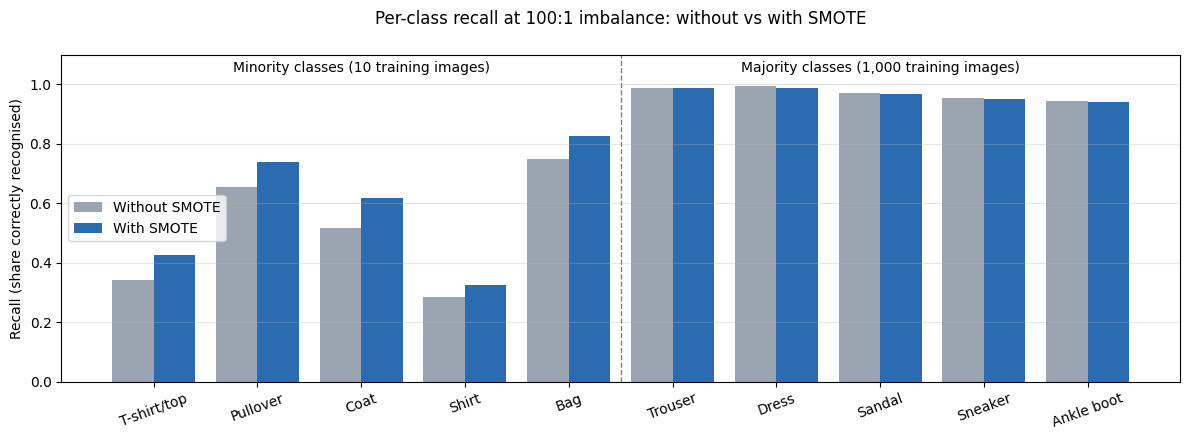

In [ ]:
rec_plain = recall_score(y_test, pred_plain, average=None)
rec_smote = recall_score(y_test, pred_smote, average=None)

per_class = pd.DataFrame({
    'class': CLASS_NAMES,
    'group': ['minority' if c in MINORITY else 'majority' for c in range(10)],
    'Without SMOTE': rec_plain,
    'With SMOTE': rec_smote,
    'Difference': rec_smote - rec_plain,
})
display(per_class.style.format({'Without SMOTE': '{:.3f}', 'With SMOTE': '{:.3f}',
                                'Difference': '{:+.3f}'}))

order = MINORITY + MAJORITY
labels = [CLASS_NAMES[c] for c in order]
x = np.arange(10)
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(x - 0.2, rec_plain[order], 0.4, label='Without SMOTE', color='#9aa5b1')
ax.bar(x + 0.2, rec_smote[order], 0.4, label='With SMOTE', color='#2b6cb0')
ax.axvline(4.5, color='grey', ls='--', lw=1)
ax.text(2, 1.04, 'Minority classes (10 training images)', ha='center', fontsize=10)
ax.text(7, 1.04, 'Majority classes (1,000 training images)', ha='center', fontsize=10)
ax.set_xticks(x); ax.set_xticklabels(labels, rotation=20)
ax.set_ylim(0, 1.1); ax.set_ylabel('Recall (share correctly recognised)')
ax.set_title('Per-class recall at 100:1 imbalance: without vs with SMOTE', pad=22)
ax.legend(loc='center left'); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('/content/smote_per_class_recall.png', dpi=200)
plt.show()

Decoding synthetic points created by SMOTE back to images

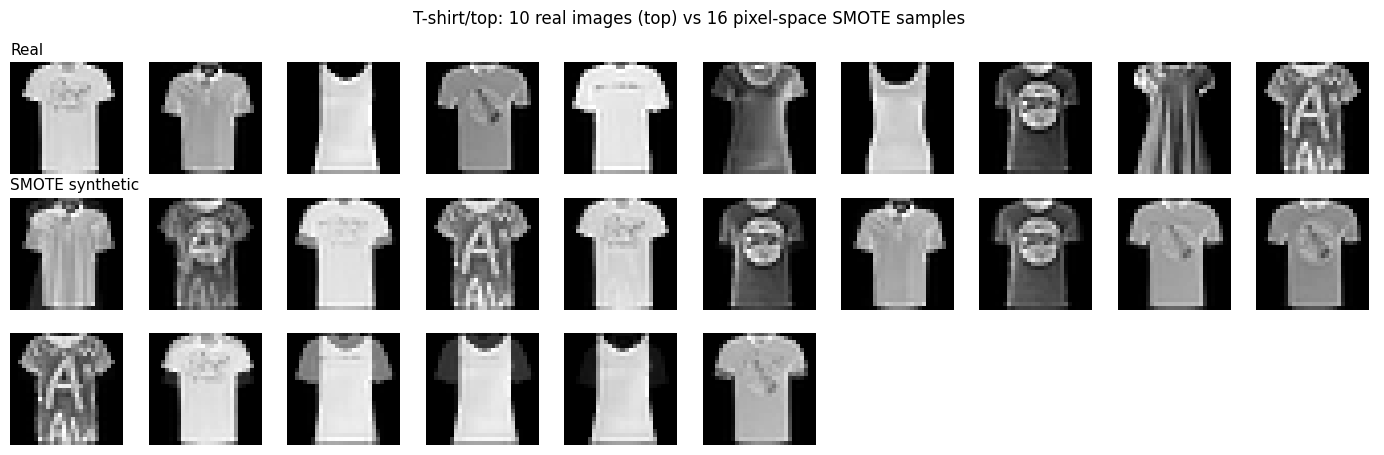

In [ ]:
# BONUS: What does a SMOTE sample look like?
# In model B, SMOTE worked on DINOv2's 768 numbers per image, which cannot be turned back into pictures. Here we run a SEPARATE SMOTE
# on the raw pixels instead, so the new samples can be shown as images.
# This is only for illustration. These are not the samples model B was trained on.

# Settings
VIS_CLASS = 0          # Class to show: 0 = T-shirt/top (a minority class with only 10 real images)
N_SYNTH   = 16         # How many synthetic T-shirts to create for the picture

# Get the training images as raw pixels.
# Each 28x28 image is flattened into one row of 784 numbers (one per pixel),because SMOTE needs every sample as a single row of numbers.
# Dividing by 255 scales pixel values from 0-255 to 0-1 (0 = black, 1 = white).
X_pix = train_ds.data.numpy()[train_idx].reshape(-1, 784) / 255.0

# Keep only the real T-shirt images (10 of them)
real = X_pix[y_train == VIS_CLASS]

# Run SMOTE to create 16 new T-shirt samples.For each new sample, SMOTE picks a real T-shirt (A), picks one of its
# 5 most similar real T-shirts (B), and creates a blend somewhere between them.
# Only the T-shirt class is topped up; all other classes are left unchanged.
sm = SMOTE(sampling_strategy={VIS_CLASS: len(real) + N_SYNTH}, k_neighbors=5, random_state=SEED)
X_res, _ = sm.fit_resample(X_pix, y_train)

# SMOTE returns the original images followed by the new ones at the end,
# so skip past the originals to keep only the 16 synthetic T-shirts
synth = X_res[len(X_pix):]

# Create a grid of image slots: 3 rows x 10 columns
fig, axes = plt.subplots(3, 10, figsize=(14, 4.6))

# Top row: the 10 real T-shirts.
# reshape(28, 28) turns each row of 784 numbers back into a 28x28 image.
for i, ax in enumerate(axes[0]):
    ax.imshow(real[i].reshape(28, 28), cmap='gray')
    ax.axis('off')     # hide the axis ticks around each image

# Rows 2 and 3: the 16 synthetic T-shirts (the last 4 of the 20 slots stay empty)
for i, ax in enumerate(axes[1:].ravel()):
    if i < len(synth):
        ax.imshow(synth[i].reshape(28, 28), cmap='gray')
    ax.axis('off')

# Labels for the rows and an overall title
axes[0, 0].set_title('Real', loc='left', fontsize=11)
axes[1, 0].set_title('SMOTE synthetic', loc='left', fontsize=11)
fig.suptitle(f'{CLASS_NAMES[VIS_CLASS]}: {len(real)} real images (top) vs '
             f'{N_SYNTH} pixel-space SMOTE samples', fontsize=12)

# Tidy the spacing, save the whole figure as ONE PNG file, and display it.
# Expect the synthetic T-shirts to look like two real ones faded together:
# SMOTE blends existing images; it does not invent new ones.
plt.tight_layout()
plt.savefig('/content/smote_pixel_samples.png', dpi=200)
plt.show()